In [453]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_circles, make_biclusters, make_blobs
from sklearn.datasets import make_classification

In [454]:
X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)

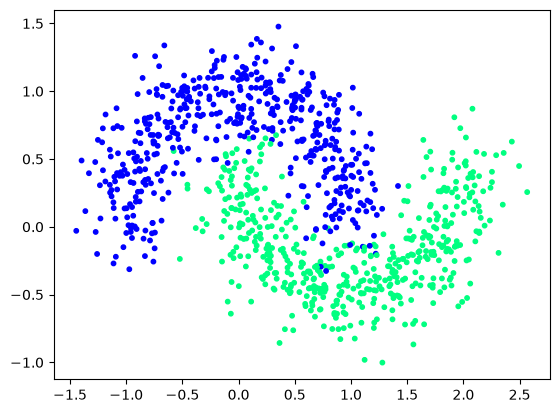

In [455]:
plt.scatter(X[:,0], X[:,1], c=y, cmap='winter', s=10)

In [456]:
X, y = make_circles(n_samples=1000, factor=0.5, noise=0.1, random_state=42)

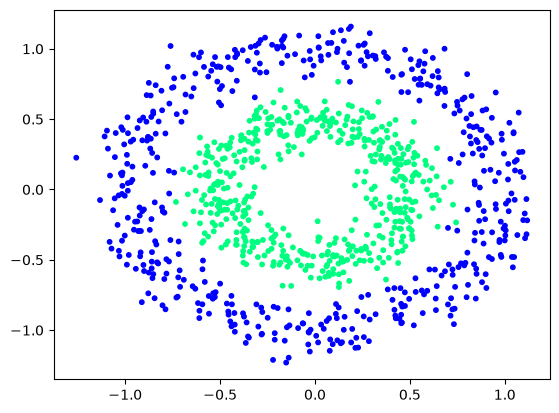

In [457]:
plt.scatter(X[:,0], X[:,1], c=y, cmap='winter', s=10)

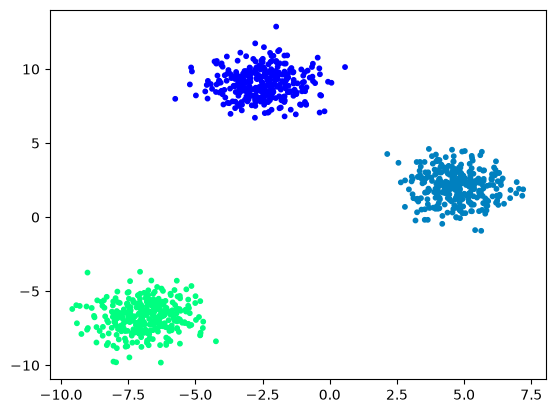

In [458]:
X, y = make_blobs(n_samples=1000, random_state=42)
plt.scatter(X[:,0], X[:,1], c=y, cmap='winter', s=10)

In [459]:
X, y = make_classification(n_samples=1000, n_features=4, n_classes=2, random_state=42)

In [460]:
df = pd.read_csv('data/Churn_Modelling.csv')

In [461]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [462]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [463]:
df.duplicated().sum()

np.int64(0)

In [464]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [465]:
df['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [466]:
df['Gender'].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

In [467]:
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='str')

In [468]:
df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

In [469]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [470]:
df = pd.get_dummies(df, columns=['Geography', 'Gender'], drop_first=True)

In [471]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False


In [472]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=['Exited'])
y = df['Exited']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [473]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [474]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, Dropout, Flatten

In [475]:
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPUs: []


In [476]:
model = Sequential([
    Input(shape=(11,)),
    Dense(10, activation='relu'),
    Dense(5, activation='relu'),
    Dense(1, activation='relu')
])


In [477]:
model.summary()

Model: "sequential_22"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_70 (Dense)                │ (None, 10)             │           120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_71 (Dense)                │ (None, 5)              │            55 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_72 (Dense)                │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 181 (724.00 B)

 Trainable params: 181 (724.00 B)

 Non-trainable params: 0 (0.00 B)

In [478]:
model.compile(loss='binary_crossentropy', optimizer='Adam', metrics=["accuracy"])

In [479]:
history = model.fit(X_train_scaled, y_train, epochs=10, validation_split=0.2)

Epoch 1/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 915us/step - accuracy: 0.7628 - loss: 0.5906 - val_accuracy: 0.7844 - val_loss: 0.5181
Epoch 2/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 513us/step - accuracy: 0.7902 - loss: 0.5028 - val_accuracy: 0.7925 - val_loss: 0.4793
Epoch 3/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 488us/step - accuracy: 0.7962 - loss: 0.4745 - val_accuracy: 0.8025 - val_loss: 0.4553
Epoch 4/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 496us/step - accuracy: 0.8008 - loss: 0.4560 - val_accuracy: 0.8106 - val_loss: 0.4388
Epoch 5/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 493us/step - accuracy: 0.8077 - loss: 0.4455 - val_accuracy: 0.8175 - val_loss: 0.4290
Epoch 6/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 491us/step - accuracy: 0.8111 - loss: 0.4379 - val_accuracy: 0.8219 - val_loss: 0.4216
Epoch 7/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 494us/step - accuracy: 0.8156 - loss: 0.4290 - val_accuracy: 0.8294 - val_loss: 0.4144
Epoch 8/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 713us/step - accuracy: 0.8209 - loss: 0.4200 - 

In [480]:
model.layers[0].get_weights()

[array([[-0.05724554,  0.40992334,  0.3114833 , -0.28643584, -0.24337189,
          0.1466284 ,  0.03394374,  0.19302061,  0.15649669, -0.01827896],
        [-0.7214306 , -0.33878577,  0.3984592 , -0.00248496, -0.23520504,
         -0.13649905,  0.23417126, -0.13520457,  0.48364273, -0.7402955 ],
        [-0.03471383, -0.2527794 ,  0.2083997 ,  0.12589072,  0.02599565,
          0.10893077, -0.43103805, -0.0054108 ,  0.21708946,  0.13155735],
        [ 0.04287598, -0.3237148 ,  0.4078645 ,  0.09779089,  0.24610136,
         -0.49171755,  0.03767574,  0.14917257,  0.3966675 ,  0.25940916],
        [ 0.0425655 ,  0.6454342 , -0.35455352, -0.54461145,  0.5108016 ,
         -0.0517539 ,  0.3106098 ,  0.58939123,  0.43762982,  0.06244199],
        [ 0.28081024, -0.3111926 , -0.43211082, -0.01137865, -0.10898749,
         -0.34239936,  0.24056695, -0.22651559,  0.258827  , -0.21779005],
        [-0.46576115,  0.01561564, -0.08767981, -0.2512999 ,  0.13237934,
          0.09011792, -0.4144696

In [481]:
model.layers[1].get_weights()

[array([[-0.37418336,  0.47437087, -0.11618531, -0.63225967,  0.11118662],
        [-0.5210194 , -0.43116376, -0.23999742,  0.3006306 ,  0.17856911],
        [ 0.10173985,  0.17923151,  0.08123051,  0.49071357, -0.51103896],
        [-0.36347675, -0.08552624,  0.5687152 ,  0.5683251 ,  0.24994715],
        [ 0.6668953 , -0.45779058, -0.5253781 ,  0.3892761 , -0.252925  ],
        [-0.4339415 , -0.61185884,  0.53000414, -0.1649729 ,  0.08805618],
        [ 0.64125276, -0.33640048,  0.09525435,  0.46556595, -0.3940351 ],
        [ 0.6576092 ,  0.43075097,  0.04290023,  0.41332617, -0.50851333],
        [ 0.44269365, -0.15911016, -0.050791  ,  0.58237517, -0.0919111 ],
        [-0.6105544 ,  0.02292338, -0.5331963 , -0.7929956 ,  0.18202141]],
       dtype=float32),
 array([ 0.03146243,  0.02943816,  0.07229454, -0.00671324, -0.04586732],
       dtype=float32)]

In [482]:
y_pred = (model.predict(X_test_scaled) > 0.5).astype(int)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 539us/step


In [483]:
from sklearn.metrics import accuracy_score

In [484]:
print("Accuracy -> ", accuracy_score(y_test, y_pred))

Accuracy ->  0.838


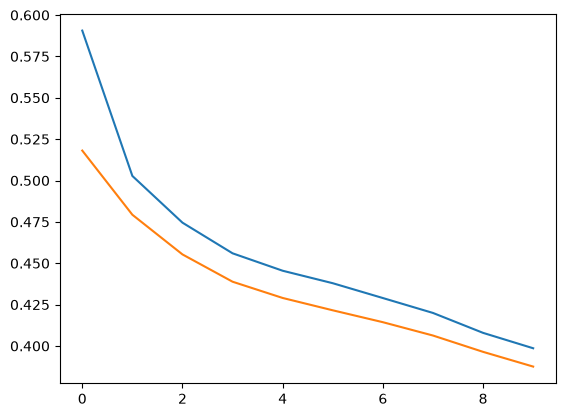

In [485]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

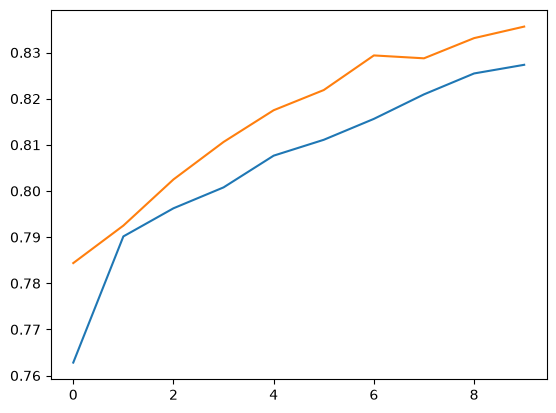

In [486]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

In [487]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

In [488]:
X_train = X_train
X_test = X_test

In [489]:
X_train.shape

(60000, 28, 28)

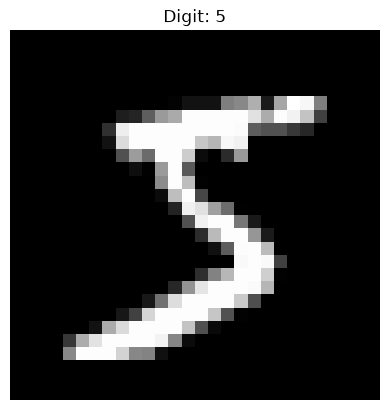

In [490]:
plt.imshow(X_train[0], cmap='grey')
plt.title(f"Digit: {y_train[0]}")
plt.axis("off")
plt.show()

In [491]:
model = Sequential([
    Input(shape=(28,28)),
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.1),
    Dense(32, activation='relu'),
    Dropout(0.1),
    Dense(16, activation='relu'),
    Dropout(0.1),
    Dense(16, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(optimizer='adam',loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [492]:
model.summary()

Model: "sequential_23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_8 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_73 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_74 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_75 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_76 (Dense)                │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_77 (Dense)                │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,290 (208.16 KB)

 Trainable params: 53,290 (208.16 KB)

 Non-trainable params: 0 (0.00 B)

In [493]:
history = model.fit(X_train, y_train, epochs=100, validation_split=0.2)

Epoch 1/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 851us/step - accuracy: 0.4341 - loss: 1.9533 - val_accuracy: 0.7189 - val_loss: 0.8204
Epoch 2/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 778us/step - accuracy: 0.7444 - loss: 0.8203 - val_accuracy: 0.8977 - val_loss: 0.3986
Epoch 3/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 836us/step - accuracy: 0.8407 - loss: 0.5494 - val_accuracy: 0.9217 - val_loss: 0.3067
Epoch 4/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 874us/step - accuracy: 0.8790 - loss: 0.4261 - val_accuracy: 0.9320 - val_loss: 0.2653
Epoch 5/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 885us/step - accuracy: 0.8957 - loss: 0.3611 - val_accuracy: 0.9418 - val_loss: 0.2201
Epoch 6/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 719us/step - accuracy: 0.9087 - loss: 0.3191 - val_accuracy: 0.9482 - val_loss: 0.1975
Epoch 7/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 726us/step - accuracy: 0.9133 - loss: 0.2947 - val_accuracy: 0.9503 - val_loss: 0.1940
Epoch 8/100
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 750us/step - accuracy: 

In [494]:
y_pred = model.predict(X_test).argmax(axis=1)
y_pred

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 493us/step


array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

In [495]:
print("Accuracy -> ", accuracy_score(y_test, y_pred))

Accuracy ->  0.9643


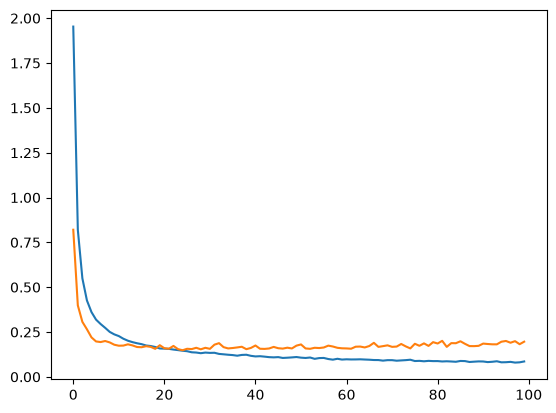

In [496]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

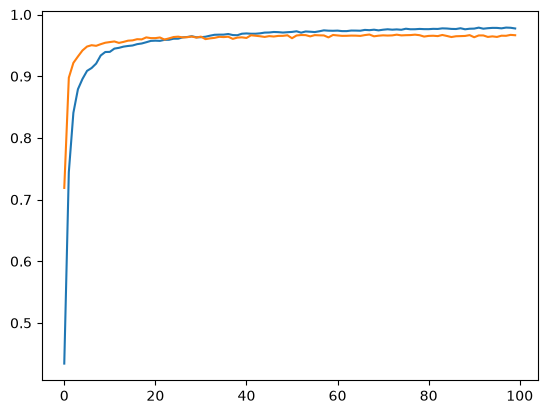

In [497]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

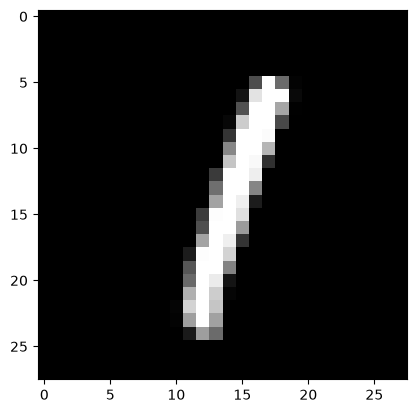

In [500]:
plt.imshow(X_test[5], cmap='grey')

In [539]:
model.predict(X_test[5].reshape(1, 28, 28)).argmax(axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


array([1])

In [540]:
df = pd.read_csv('data/Admission_Predict.csv')
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [541]:
df = df.drop(columns=['Serial No.'])

In [542]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   GRE Score          400 non-null    int64  
 1   TOEFL Score        400 non-null    int64  
 2   University Rating  400 non-null    int64  
 3   SOP                400 non-null    float64
 4   LOR                400 non-null    float64
 5   CGPA               400 non-null    float64
 6   Research           400 non-null    int64  
 7   Chance of Admit    400 non-null    float64
dtypes: float64(4), int64(4)
memory usage: 25.1 KB


In [545]:
df.shape

(400, 8)

In [544]:
X = df.drop(columns=["Chance of Admit"])
y = df['Chance of Admit']

In [546]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [547]:
from sklearn.preprocessing import MinMaxScaler

In [548]:
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [614]:
model = Sequential([
    Input(shape=(7,)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1, activation='linear')
])

model.compile(loss='mse', optimizer='adam', metrics=['mae'])

In [615]:
model.summary()

Model: "sequential_37"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_126 (Dense)               │ (None, 32)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_127 (Dense)               │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_129 (Dense)               │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,073 (4.19 KB)

 Trainable params: 1,073 (4.19 KB)

 Non-trainable params: 0 (0.00 B)

In [616]:
history = model.fit(X_train_scaled, y_train, epochs=100, validation_split=0.2)

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.9258 - mae: 0.9329 - val_loss: 0.7928 - val_mae: 0.8654
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6183 - mae: 0.7667 - val_loss: 0.5363 - val_mae: 0.7179
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4465 - mae: 0.6545 - val_loss: 0.3985 - val_mae: 0.6201
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3404 - mae: 0.5723 - val_loss: 0.3131 - val_mae: 0.5479
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2621 - mae: 0.5010 - val_loss: 0.2347 - val_mae: 0.4722
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1871 - mae: 0.4204 - val_loss: 0.1578 - val_mae: 0.3842
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1131 - mae: 0.3230 - val_loss: 0.0805 - val_mae: 0.2716
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0465 - mae: 0.1993 - val_loss: 0.0200 - val_mae: 0.1336
Epoch 9/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0097 - mae: 0.0801 -

In [617]:
y_pred = model.predict(X_test_scaled)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


In [618]:
from sklearn.metrics import r2_score
r2_score(y_test, y_pred)

0.8272679425686748

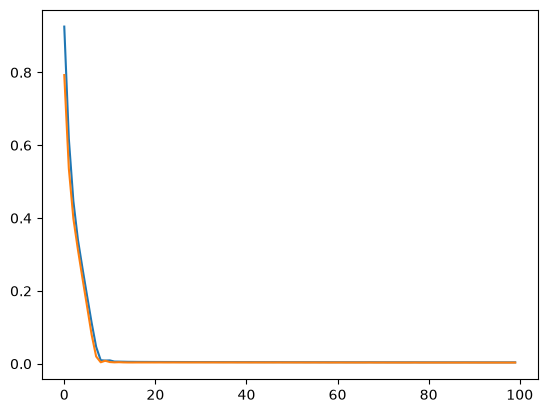

In [619]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

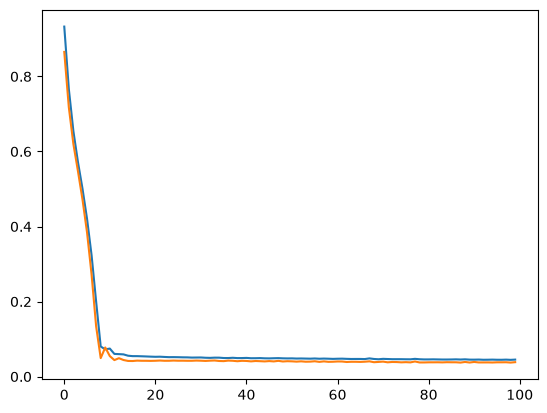

In [620]:
plt.plot(history.history['mae'])
plt.plot(history.history['val_mae'])